# Unit 3 · Exercise 2: Simple linear regression

Executed learning workbook, prepared 5 November 2026. Adapted from the supplied University of Essex Online notebook. The original examples appear first, followed by controlled experiments and interpretation.

**How to use:** Run all cells from top to bottom. Find **Change these values**, change one setting, then run all again. Keep the random seed fixed when comparing a change in noise or model settings. Read the printed results alongside the plots; outputs describe these teaching datasets only.

**Corrections and provenance:** Corrected stat.linregress and stat.pearsonr to stats.linregress and stats.pearsonr. The fitted line is plotted in sorted x order. Original data and prediction at x = 10 are retained.

The supplied activity specifies running and varying four programs; it does not specify an essay word count or a separate submission format. These notebooks provide execution evidence and observations. Review and personalise the final reflection prompts yourself.

## 1. Original example (corrected where needed)

**Execution note:** All code cells were executed in order in a fresh local IPython session, with actual printed results and figures captured below. This environment does not permit the socket-based Jupyter kernel launcher. Rerun in your own Jupyter or Colab session for your course workflow.

Pearsons correlation: -0.759


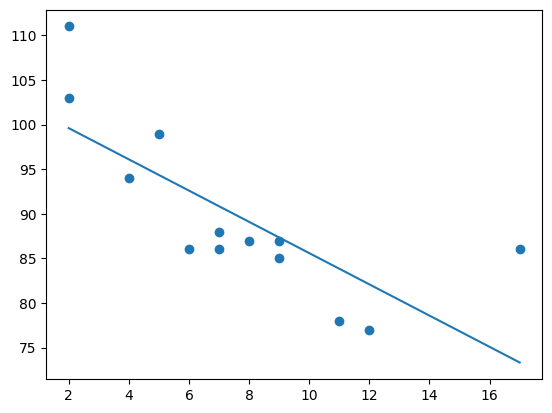

In [1]:
import matplotlib.pyplot as plt
from scipy import stats

#Create the arrays that represent the values of the x and y axis
x = [5,7,8,7,2,17,2,9,4,11,12,9,6]
y = [99,86,87,88,111,86,103,87,94,78,77,85,86]

#Execute a method that returns some important key values of Linear Regression
slope, intercept, r, p, std_err = stats.linregress(x, y)

# measure the correlation 
corr, _ = stats.pearsonr(x, y)
print('Pearsons correlation: %.3f' % corr)

#Create a function that uses the slope and intercept values to return a new value. 
#This new value represents where on the y-axis the corresponding x value will be placed
def myfunc(x):
  return slope * x + intercept

#Run each value of the x array through the function. This will result in a new array with new values for the y-axis
mymodel = list(map(myfunc, x))

#Draw the original scatter plot & the line of linear regression
plt.scatter(x, y)
plt.plot(sorted(x), list(map(myfunc, sorted(x))))
plt.show()


## Predict Future Values

In [2]:
from scipy import stats

x = [5,7,8,7,2,17,2,9,4,11,12,9,6]
y = [99,86,87,88,111,86,103,87,94,78,77,85,86]

slope, intercept, r, p, std_err = stats.linregress(x, y)

def myfunc(x):
  return intercept + slope * x 

speed = myfunc(10)

print(speed)

85.59308314937454


If x=10 then predicted y is 85.59

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import r2_score, mean_squared_error
from IPython.display import display
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.2, 'font.size': 10})

## 2. Change data points and refit
Each scenario starts from the original arrays. The offset, noise and outlier experiments are independent of each other. R² here is a training score, not evidence of accuracy on unseen cases.

Baseline: y = 103.1060 + (-1.7513)x


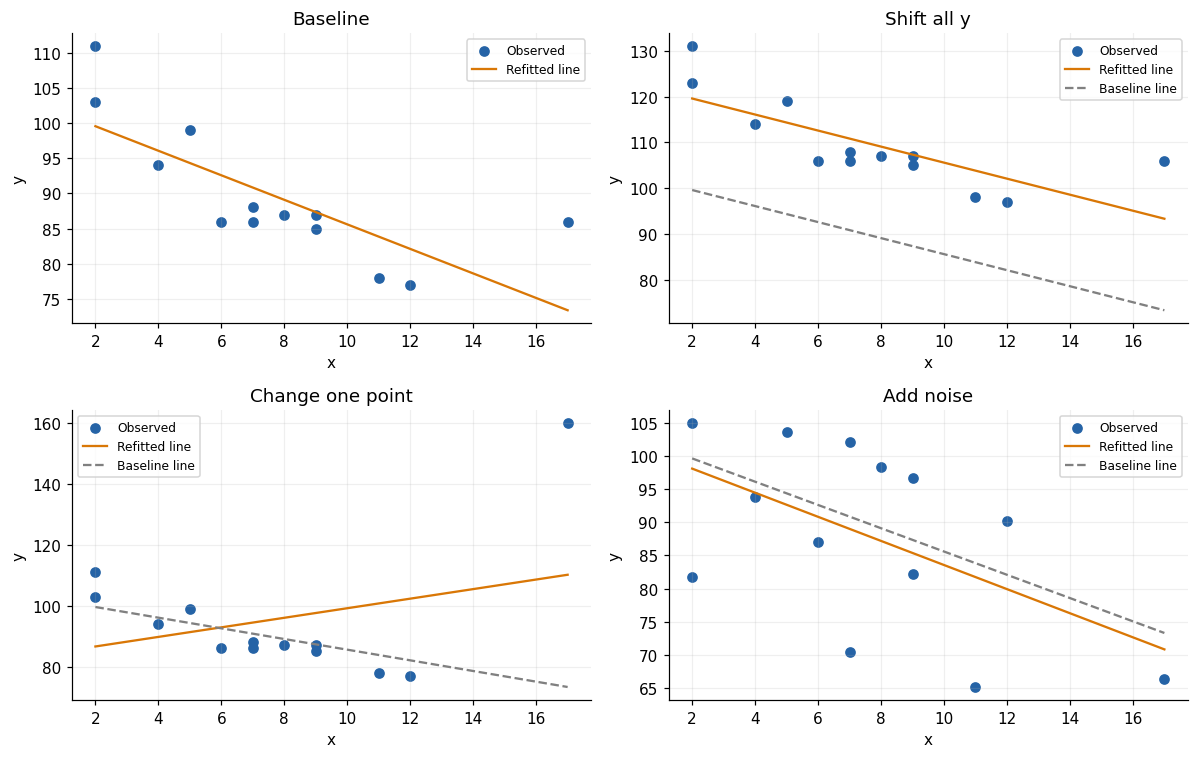

,Scenario,Slope,Intercept,Pearson r,Training R2,Prediction at chosen x
0,Baseline,-1.7513,103.1060,-0.7586,0.5755,85.5931
1,Shift all y,-1.7513,123.1060,-0.7586,0.5755,105.5931
2,Change one point,1.5703,83.5033,0.3031,0.0919,99.2060
3,Add noise,-1.8136,101.6965,-0.5454,0.2974,83.5610


In [4]:
# Change these values, then run all cells again.
Y_OFFSET = 20
OUTLIER_Y = 160
NOISE_SD = 15
PREDICT_X = 10
RANDOM_SEED = 42
x_base = np.array([5,7,8,7,2,17,2,9,4,11,12,9,6], dtype=float)
y_base = np.array([99,86,87,88,111,86,103,87,94,78,77,85,86], dtype=float)
y_outlier = y_base.copy()
y_outlier[np.argmax(x_base)] = OUTLIER_Y
y_noise = y_base + np.random.default_rng(RANDOM_SEED).normal(0, NOISE_SD, len(y_base))
variants={'Baseline':y_base, 'Shift all y':y_base+Y_OFFSET, 'Change one point':y_outlier, 'Add noise':y_noise}
rows=[]
fig,axes=plt.subplots(2,2,figsize=(11,7))
grid=np.linspace(x_base.min(),x_base.max(),150)
baseline_fit=stats.linregress(x_base,y_base)
for ax,(name,yy) in zip(axes.flat,variants.items()):
    fit=stats.linregress(x_base,yy)
    pred=fit.intercept+fit.slope*x_base
    rows.append({'Scenario':name,'Slope':fit.slope,'Intercept':fit.intercept,'Pearson r':fit.rvalue,
                 'Training R2':r2_score(yy,pred),'Prediction at chosen x':fit.intercept+fit.slope*PREDICT_X})
    ax.scatter(x_base,yy,color='#2563a6',label='Observed')
    ax.plot(grid,fit.intercept+fit.slope*grid,color='#d97706',label='Refitted line')
    if name!='Baseline':
        ax.plot(grid,baseline_fit.intercept+baseline_fit.slope*grid,'--',color='gray',label='Baseline line')
    ax.set(title=name,xlabel='x',ylabel='y'); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()
linear_results=pd.DataFrame(rows)
display(linear_results.round(4))
print(f'Baseline: y = {baseline_fit.intercept:.4f} + ({baseline_fit.slope:.4f})x')

## 3. Interpretation
The baseline has a negative association. Adding a constant to every y value moves the intercept and prediction by that constant, while leaving slope, Pearson r and R² unchanged. Changing the point at the largest x can strongly rotate the fitted line because it has high leverage; whether it is influential also depends on its y value. Noise changes the fitted coefficients and the strength of association.

**Try next:** Set OUTLIER_Y to 120 and then 200. Set Y_OFFSET to −20. Record how the slope and predicted y change. Do not delete an unusual observation without investigating it. Predictions outside x = 2 to 17 are extrapolations. The source's speed example is a teaching illustration, not a validated traffic model.

## Professional interpretation and personal reflection

- **Dataset suitability:** These are synthetic or small teaching datasets. A strong fit does not establish representativeness, causation or fitness for operational use.
- **Ethical and social issues:** Do not remove inconvenient outliers to improve a score. Investigate whether they are errors or valid cases; rare cases can matter disproportionately in real decisions. Report uncertainty and subgroup limitations.
- **Legal and professional issues:** Before using real personal data, establish the applicable permission or lawful basis, privacy safeguards and data-use terms. These examples do not demonstrate legal compliance. Preserve provenance, units, changes and reproducible execution evidence.
- **Your reflection:** Which change did you rerun? What did you expect, what actually changed, and what would you check before using the model for a real decision? Write your own answers after inspecting the results.

## References
University of Essex Online (2026) *Unit03 Ex2 linear_regression* [teaching notebook supplied with the activity].

SciPy developers (n.d.) *linregress*. Available at: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.linregress.html (Accessed: 5 November 2026).